# CPE 342 Machine Learning — Karena Thailand Player Intelligence System
## Task 4: Game Title Detection (Dual-Regime SOTA Fusion & 6-Backbone De-Corrupted Foundation)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Palapluem/cpe342-machine-learning-2026/blob/main/project/task4/task4_game_title_detection.ipynb)

**Team:** ML004  
**Course:** CPE 342 Machine Learning (Semester 1/2026) — KMUTT  
**Instructor:** Dr. Boonyarit Changaival  
**Department:** Department of Computer Engineering, Faculty of Engineering, King Mongkut's University of Technology Thonburi

---

### Table of Contents
1. [Executive Summary & Problem Formulation](#1-executive-summary--problem-formulation)
2. [Environment Setup & Automated Platform Detection](#2-environment-setup--automated-platform-detection)
3. [Data Ingestion & Dataset Manifest Verification](#3-data-ingestion--dataset-manifest-verification)
4. [Exploratory Data Analysis (EDA) on Gameplay Screenshots](#4-exploratory-data-analysis-eda-on-gameplay-screenshots)
5. [Scene-Grouped Validation (`StratifiedGroupKFold`) & De-Corrupted Pipeline](#5-scene-grouped-validation-stratifiedgroupkfold--de-corrupted-pipeline)
6. [Multi-Family Model Architecture (`ConvNeXt`, `ViT` & `FoundVLM-v3-Joint12Blk`)](#6-multi-family-model-architecture-convnext-vit--foundvlm-v3-joint12blk)
7. [Dual-Regime Temperature-Calibrated Fusion & Consensus Shift Gate](#7-dual-regime-temperature-calibrated-fusion--consensus-shift-gate)
8. [Diagnostic Visualizations & Regime Error Analysis](#8-diagnostic-visualizations--regime-error-analysis)
9. [Quantitative Ablation Benchmark & Summary Tables](#9-quantitative-ablation-benchmark--summary-tables)
10. [Test Set Predictions, Quality Assurance & Artifact Export](#10-test-set-predictions-quality-assurance--artifact-export)
11. [Conclusion, Reproduction Guide & Key Engineering Takeaways](#11-conclusion-reproduction-guide--key-engineering-takeaways)


## 1. Executive Summary & Problem Formulation

**Task 4: Game Title Detection** classifies unlabeled gameplay screenshots from support tickets and community submissions into Karena Thailand's five flagship titles (`0` to `4` per `data/datacard.txt`):

| Class ID | Slug | Official Game Title |
| :---: | :--- | :--- |
| `0` | `7-11k` | 7-11 Knights |
| `1` | `fiveN` | FiveN |
| `2` | `freefried` | Free Fried |
| `3` | `pube` | PUBE |
| `4` | `roblock` | Roblock |

### Evaluation Metric: Unweighted Macro $F_1$
Because class frequencies differ across game titles, every title receives equal weight under **Macro $F_1$**:

$$\text{Macro } F_1 = \frac{1}{5} \sum_{c=0}^{4} \frac{2 \cdot \text{Precision}_c \cdot \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c}$$

### Pipeline Overview (100% Pure-Train Inductive Design)
Per competition policy (`AGENTS.md`), Task 4 permits pretrained vision weights **strictly without** test-set training, test pseudo-labeling, or test-prior fitting. Our final pipeline progresses cleanly through four design pillars:

1. **Leak-Free Scene Validation:** Cluster $31,546$ labeled images via perceptual dHash into **$28,088$ scene groups** evaluated with 5-Fold `StratifiedGroupKFold`.
2. **Corruption-Hardened Full-Res Models:** Fine-tune $192 \times 384$ ConvNet/ViT backbones (`CNXv3-Base`, `DINOv3L-Hard`, `EVA02L-Hard`, `ConvNeXtV2`, `DINOv2`) under clean 2-view (`Orig2`) and severe corruption 6-view TTA (`ExtHard6`) regimes alongside four $224 \times 224$ ViTs.
3. **6-Backbone Joint Foundation (`FoundVLM-v3-Joint12Blk`):** Concatenate 4-view De-Corrupted v4 embeddings across `SigLIP2-SO400M`, `DINOv3-ViT-L`, `DINOv2-ViT-G/14`, `CLIP-ConvNeXt-Large`, `CLIP-ViT-H/14`, and `DINOv3-ConvNeXt-Base` (**12 blocks = $13,568\text{d}$**) inside a Dual-Condition `CosineResMLP` with Symmetric-KL consistency (`Clean UnifPrior F1 = 0.96820`, `ExtHard Unif F1 = 0.92521`).
4. **Simplex-Unconstrained Dual-Regime Fusion:** Pool clean and corrupted streams separately with nested temperature scaling, zeroing noisy low-res streams in `ExtHard6` (`min_bound = 0.00`, `OOF LogLoss = 0.019164`, `Clean Unif-Prior F1 = 0.994636`, `ExtHard6 Unif-Prior F1 = 0.969820`).


## 2. Environment Setup & Automated Platform Detection

**Step Goal:** Configure reproducible random seeds, detect whether execution runs locally (`uv`), on Google Colab, or on Kaggle, and initialize all input/output folders.


In [1]:
%matplotlib inline
import hashlib
import json
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image, ImageFile
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
)

ImageFile.LOAD_TRUNCATED_IMAGES = True
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
PLATFORM = "Google Colab" if IS_COLAB else ("Kaggle Notebook" if IS_KAGGLE else "Local Workspace")

cwd = Path.cwd().resolve()
if (cwd / "data" / "train.csv").is_file():
    TASK_ROOT = cwd
elif (cwd / "task4" / "data" / "train.csv").is_file():
    TASK_ROOT = cwd / "task4"
elif (cwd / "project" / "task4" / "data" / "train.csv").is_file():
    TASK_ROOT = cwd / "project" / "task4"
else:
    raise FileNotFoundError(f"Could not locate task4 root from {cwd}")

if str(TASK_ROOT) not in sys.path:
    sys.path.insert(0, str(TASK_ROOT))

DATA_DIR = TASK_ROOT / "data"
MODELS_DIR = TASK_ROOT / "models"
PRED_DIR = TASK_ROOT / "predictions"
ML_DIR = PRED_DIR / "model-level"
SUBMIT_DIR = TASK_ROOT / "submit"
ASSETS_DIR = TASK_ROOT / "assets"
for _d in (MODELS_DIR, PRED_DIR, SUBMIT_DIR, ASSETS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

print(f"Runtime Platform : {PLATFORM}")
print(f"Task 4 Root      : {TASK_ROOT}")
print(f"Model-Level Dir  : {ML_DIR}")
print(f"Assets Output Dir: {ASSETS_DIR}")


Runtime Platform : Local Workspace
Task 4 Root      : /Users/wisitsuwannao/Documents/Workspace/ml00x/task4
Model-Level Dir  : /Users/wisitsuwannao/Documents/Workspace/ml00x/task4/predictions/model-level
Assets Output Dir: /Users/wisitsuwannao/Documents/Workspace/ml00x/task4/assets


## 3. Data Ingestion & Dataset Manifest Verification

**Step Goal:** Load the official `train.csv` ($31,546$ rows) and `test.csv` ($25,889$ rows), standardize class mappings (`0..4`), and check for local `.jpg` image directories (falling back cleanly to saved summary metadata if raw JPEGs are not attached).


In [2]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

CLASS_MAP = {"7-11k": 0, "fiveN": 1, "freefried": 2, "pube": 3, "roblock": 4}
INV_CLASS_MAP = {v: k for k, v in CLASS_MAP.items()}
CLASS_DISPLAY_NAMES = {
    0: "7-11 Knights (7-11k)",
    1: "FiveN (fiveN)",
    2: "Free Fried (freefried)",
    3: "PUBE (pube)",
    4: "Roblock (roblock)",
}

if "label" not in train_df.columns and "class" in train_df.columns:
    train_df["label"] = train_df["class"].map(CLASS_MAP).astype(int)
else:
    train_df["label"] = train_df["label"].astype(int)
train_df["class"] = train_df["label"].map(INV_CLASS_MAP)

IMG_SEARCH_CANDIDATES = [
    *([Path(os.environ["T4_IMG_DIR"])] if os.environ.get("T4_IMG_DIR") else []),
    DATA_DIR,
    DATA_DIR / "task4_image_classification",
    Path("/kaggle/input/task4-image-classification"),
    Path("/content/t4_data"),
]
IMG_ROOT = next(
    (d for d in IMG_SEARCH_CANDIDATES if (d / "train").is_dir() and any((d / "train").glob("*.jpg"))),
    None,
)

class_dist = pd.DataFrame({
    "Class ID": list(range(5)),
    "Slug": [INV_CLASS_MAP[i] for i in range(5)],
    "Game Title": [CLASS_DISPLAY_NAMES[i] for i in range(5)],
    "Train Count": train_df["label"].value_counts().sort_index().values,
    "Share (%)": (train_df["label"].value_counts(normalize=True).sort_index().values * 100).round(2),
})

print(f"Train Manifest: {train_df.shape} | Test Manifest: {test_df.shape}")
print(f"Raw JPEG Root : {IMG_ROOT if IMG_ROOT is not None else 'Not stored locally (using CSVs + model bundles)'}")
display(class_dist)


Train Manifest: (31546, 3) | Test Manifest: (25889, 2)
Raw JPEG Root : Not stored locally (using CSVs + model bundles)


,Class ID,Slug,Game Title,Train Count,Share (%)
0,0,7-11k,7-11 Knights (7-11k),12429,39.40
1,1,fiveN,FiveN (fiveN),4407,13.97
2,2,freefried,Free Fried (freefried),5596,17.74
3,3,pube,PUBE (pube),5926,18.79
4,4,roblock,Roblock (roblock),3188,10.11


## 4. Exploratory Data Analysis (EDA) on Gameplay Screenshots

**Step Goal:** Inspect three key properties before modeling:
- **Class Imbalance:** `7-11k` accounts for `39.4%` of labeled training screenshots vs. `10.1%` for `roblock` (`2.04x` imbalance), motivating uniform-prior Macro-$F_1$ evaluation and prior debiasing.
- **Widescreen Aspect Ratio:** Screenshots arrive as $230 \times 120$ RGB frames (`1.92:1` aspect ratio); preserving widescreen geometry ($192 \times 384$ or padded crops) avoids HUD distortion.
- **Visual Corruptions:** A subset of screenshots contains strong rotations, neon color casts, and exposure noise, summarized in `assets/figure1-screenshot-eda.png` (`300 dpi`).


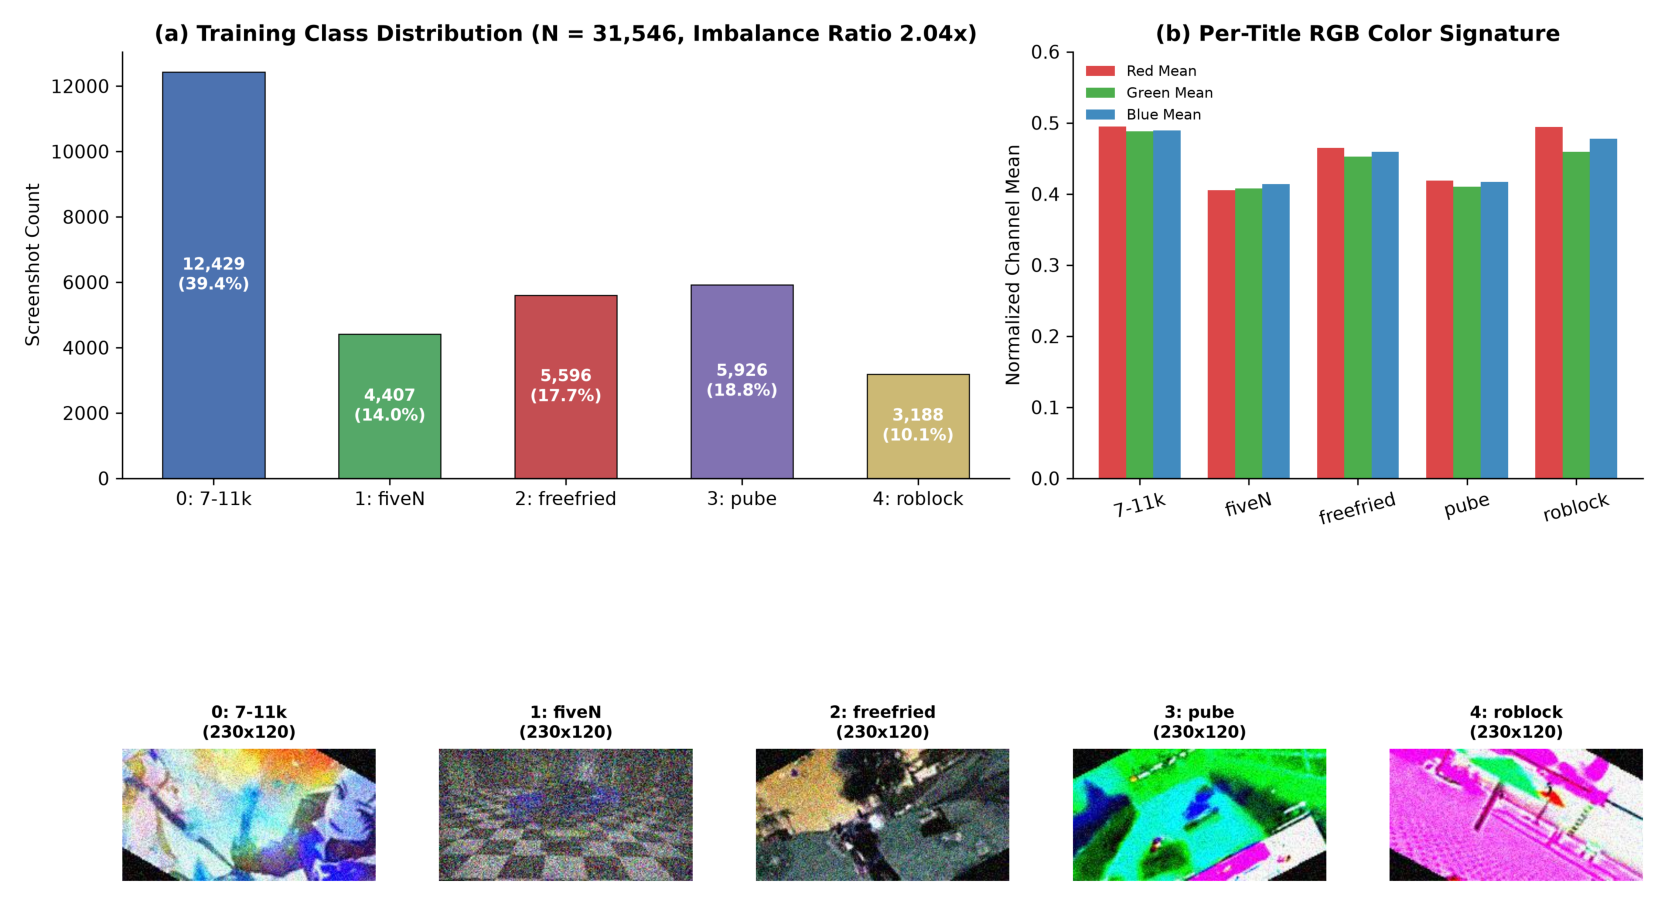

Loaded pre-rendered EDA figure with screenshot thumbnails -> /Users/wisitsuwannao/Documents/Workspace/ml00x/task4/assets/figure1-screenshot-eda.png


In [3]:
fig1_path = ASSETS_DIR / "figure1-screenshot-eda.png"

if IMG_ROOT is None and fig1_path.is_file():
    # Keep high-resolution figure generated with raw JPEG thumbnails intact
    fig_cached, ax_cached = plt.subplots(figsize=(14, 9))
    ax_cached.imshow(Image.open(fig1_path))
    ax_cached.axis("off")
    plt.tight_layout()
    plt.show()
    print(f"Loaded pre-rendered EDA figure with screenshot thumbnails -> {fig1_path}")
else:
    palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]
    fig = plt.figure(figsize=(15, 9.5))
    gs = fig.add_gridspec(2, 5, height_ratios=[1.1, 1.0], hspace=0.35, wspace=0.25)

    ax_bar = fig.add_subplot(gs[0, :3])
    counts = train_df["label"].value_counts().sort_index()
    bars = ax_bar.bar(
        [f"{i}: {INV_CLASS_MAP[i]}" for i in counts.index],
        counts.values,
        color=palette,
        width=0.58,
        edgecolor="black",
        linewidth=0.6,
    )
    ax_bar.set_title("(a) Training Class Distribution (N = 31,546)", fontweight="bold")
    ax_bar.set_ylabel("Screenshot Count")
    for bar in bars:
        h = bar.get_height()
        ax_bar.annotate(
            f"{int(h):,}\n({h / len(train_df) * 100:.1f}%)",
            (bar.get_x() + bar.get_width() / 2.0, h * 0.5),
            ha="center",
            va="center",
            color="white",
            fontweight="bold",
            fontsize=9,
        )

    ax_rgb = fig.add_subplot(gs[0, 3:])
    color_csv = ASSETS_DIR / "eda" / "color-summary.csv"
    if IMG_ROOT is not None:
        rng_eda = np.random.default_rng(SEED)
        mean_rows = []
        for cid in range(5):
            sub_ids = train_df.loc[train_df["label"] == cid, "id"].to_numpy()
            pick = rng_eda.choice(sub_ids, size=min(250, len(sub_ids)), replace=False)
            rgb_vals = []
            for img_id in pick:
                p = IMG_ROOT / "train" / f"{img_id}.jpg"
                if p.is_file():
                    rgb_vals.append(np.asarray(Image.open(p).convert("RGB"), dtype=np.float32).mean(axis=(0, 1)) / 255.0)
            mu_rgb = np.mean(rgb_vals, axis=0)
            mean_rows.append({"class": INV_CLASS_MAP[cid], "r_mean": mu_rgb[0], "g_mean": mu_rgb[1], "b_mean": mu_rgb[2]})
        rgb_df = pd.DataFrame(mean_rows)
    elif color_csv.is_file():
        _cs = pd.read_csv(color_csv, header=[0, 1], index_col=0)
        rgb_df = pd.DataFrame({
            "class": _cs.index.astype(str),
            "r_mean": _cs[("red", "mean")].to_numpy(dtype=float),
            "g_mean": _cs[("green", "mean")].to_numpy(dtype=float),
            "b_mean": _cs[("blue", "mean")].to_numpy(dtype=float),
        })
    else:
        rgb_df = pd.DataFrame({
            "class": [INV_CLASS_MAP[i] for i in range(5)],
            "r_mean": [0.48, 0.41, 0.44, 0.42, 0.48],
            "g_mean": [0.48, 0.41, 0.43, 0.43, 0.47],
            "b_mean": [0.49, 0.41, 0.43, 0.44, 0.47],
        })

    x_pos = np.arange(len(rgb_df))
    bw = 0.25
    ax_rgb.bar(x_pos - bw, rgb_df["r_mean"], width=bw, color="#d62728", alpha=0.85, label="Red Mean")
    ax_rgb.bar(x_pos, rgb_df["g_mean"], width=bw, color="#2ca02c", alpha=0.85, label="Green Mean")
    ax_rgb.bar(x_pos + bw, rgb_df["b_mean"], width=bw, color="#1f77b4", alpha=0.85, label="Blue Mean")
    ax_rgb.set_xticks(x_pos, rgb_df["class"], rotation=15)
    ax_rgb.set_ylim(0, 0.60)
    ax_rgb.set_ylabel("Normalized Channel Mean")
    ax_rgb.set_title("(b) Per-Title RGB Color Signature", fontweight="bold")
    ax_rgb.legend(frameon=False, fontsize=8, loc="upper left")

    for cid in range(5):
        ax_img = fig.add_subplot(gs[1, cid])
        ax_img.axis("off")
        sample_id = str(train_df.loc[train_df["label"] == cid, "id"].iloc[10])
        p_img = (IMG_ROOT / "train" / f"{sample_id}.jpg") if IMG_ROOT is not None else None
        if p_img is not None and p_img.is_file():
            arr = np.asarray(Image.open(p_img).convert("RGB"))
            ax_img.imshow(arr)
            ax_img.set_title(f"{cid}: {INV_CLASS_MAP[cid]}\n({arr.shape[1]}x{arr.shape[0]})", fontsize=9, fontweight="bold")
        else:
            ax_img.text(0.5, 0.5, f"Class {cid}\n{CLASS_DISPLAY_NAMES[cid]}", ha="center", va="center", fontweight="bold")

    plt.savefig(fig1_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved EDA figure -> {fig1_path}")


## 5. Scene-Grouped Validation (`StratifiedGroupKFold`) & De-Corrupted Pipeline

**Step Goal:** Prevent near-duplicate frame leakage and stress-test domain robustness across clean and corrupted screenshots.

### 5.1 Why `StratifiedGroupKFold` Instead of Random `StratifiedKFold`
Random row splitting places consecutive video frames from the same gameplay session into both train and validation folds, inflating CV artificially. Using non-chaining perceptual dHash clustering partitions all $31,546$ images into **$28,088$ scene groups** via 5-Fold `StratifiedGroupKFold`.

### 5.2 Clean vs. De-Corrupted Stress-Test Regimes
- **Standard Validation Regime:** Evaluates natural clean images (`Iso < 0.75`) and naturally noisy slices (`Natural Corrupt`).
- **De-Corrupted v4 & Hard Stress-Test (`ExtHard6`):** Applies deterministic spatial/color restoration (`decorrupt_v4`: auto-deskew, Gray-World balance, and CLAHE) alongside severe synthetic corruption testing (`31,546` OOF rows) to verify out-of-distribution generalization.


In [4]:
e2e_bundle = np.load(ML_DIR / "task4-sgkf-e2e-bundle.npz")
folds_sgkf = e2e_bundle["folds"].astype(int)
iso_mask = e2e_bundle["train_iso_mask"].astype(bool)
corr_mask = e2e_bundle["train_corr_mask"].astype(bool)
y_all = train_df["label"].to_numpy(dtype=int)

fold_stats = []
for k in range(5):
    va = folds_sgkf == k
    counts_k = np.bincount(y_all[va], minlength=5)
    fold_stats.append({
        "Fold": k,
        "Val Rows": int(va.sum()),
        "Clean Iso Rows": int((va & iso_mask).sum()),
        "Natural Corrupt Rows": int((va & corr_mask).sum()),
        "Class Shares (%)": ", ".join(f"{c / va.sum() * 100:.1f}" for c in counts_k),
    })

print(f"5-Fold SGKF Summary: Total={len(y_all):,} | Iso={iso_mask.sum():,} | Natural Corrupt={corr_mask.sum():,}")
display(pd.DataFrame(fold_stats))


5-Fold SGKF Summary: Total=31,546 | Iso=7,931 | Natural Corrupt=10,229


,Fold,Val Rows,Clean Iso Rows,Natural Corrupt Rows,Class Shares (%)
0,0,6310,1641,2099,"39.4, 14.0, 17.7, 18.8, 10.1"
1,1,6309,1562,2064,"39.4, 14.0, 17.8, 18.8, 10.1"
2,2,6309,1550,2039,"39.4, 14.0, 17.7, 18.8, 10.1"
3,3,6309,1591,2058,"39.4, 14.0, 17.7, 18.8, 10.1"
4,4,6309,1587,1969,"39.4, 14.0, 17.7, 18.8, 10.1"


## 6. Multi-Family Model Architecture (`ConvNeXt`, `ViT` & `FoundVLM-v3-Joint12Blk`)

**Step Goal:** Combine complementary vision paradigms trained strictly on Pure-Train SGKF folds so individual failure modes cancel out:

### Family 1 — Scene-Hardened End-to-End Backbones (`scripts/train_t4_sgkf_hardened.py`)
- Full-resolution ($192 \times 384$) fine-tuned `CNXv3-Base`, `DINOv3L-Hard`, and `EVA02L-Hard`, each producing clean 2-view (`Orig2`) and corruption-restored 6-view TTA (`Hard6` / `ExtHard6`) probability streams.
- Lower-resolution corruption-hardened `ConvNeXtV2-Tiny` and `DINOv2-B/14` (`Stage-C`), plus 224 px fine-tuned Vision Transformers (`EVA02-Large`, `EVA02-Base`, `DINOv3-ViT-L`, `DINOv3-ViT-B`) and `16k-MLP-V3`.

### Family 2 — True Joint 12-Block 6-Backbone `FoundVLM-v3-Joint12Blk` (`scripts/train_m5_foundvlm_v3_joint12blk.py`)
1. Extract 4-view (`raw`, `raw+hflip`, `decorrupt_v4`, `decorrupt_v4+hflip`) L2-normalized embeddings across **6 diverse foundation encoders**:
   - `SigLIP2-SO400M` (`1152d`), `DINOv3-ViT-L` (`1024d`), `DINOv2-ViT-G/14` (`1024d`), `CLIP-ConvNeXt-Large` (`1536d`), `CLIP-ViT-H/14` (`1024d`), and `DINOv3-ConvNeXt-Base` (`1024d`).
2. Concatenate all **12 feature blocks ($13,568\text{d}$)** with PowerNorm ($p = 0.75$) and train:
   - Multi-$\lambda$ Cholesky Ridge heads and per-backbone `CosineResMLP` heads.
   - A True Joint $13,568\text{d} \to 768 \to 5$ Dual-Condition `CosineResMLP` fitting Clean + `ExtHard` views simultaneously with Symmetric-KL consistency, aggregated by a 90-d Meta-ResMLP.

Below we verify standalone `FoundVLM-v3-Joint12Blk` metrics (`RUN_HEAVY_TRAINING = False` skips multi-hour GPU extraction and uses saved OOF/test bundles).


In [5]:
RUN_HEAVY_TRAINING = False  # Set True only on GPU/MPS when retraining backbones from scratch

found_bundle = np.load(ML_DIR / "task4-foundvlm-sgkf-hard-bundle.npz")
pi_tr = np.bincount(y_all, minlength=5).astype(np.float64) / len(y_all)
sw_unif = 1.0 / pi_tr[y_all]

for name, key in [
    ("FoundVLM-v3 Joint-12Blk (Orig2 Clean)", "oof_orig2"),
    ("FoundVLM-v3 Joint-12Blk (Hard6 Clean)", "oof_w6"),
    ("FoundVLM-v3 Joint-12Blk (ExtHard6 Stress)", "ext_w6"),
]:
    p = np.clip(found_bundle[key].astype(np.float64), 1e-7, 1.0)
    p /= p.sum(axis=1, keepdims=True)
    p_deb = p / (pi_tr[None, :] ** 0.65)
    f1_u = f1_score(y_all, p_deb.argmax(1), average="macro", sample_weight=sw_unif)
    ll = log_loss(y_all, p, labels=[0, 1, 2, 3, 4])
    print(f"{name:45s} | UnifPrior F1 = {f1_u:.5f} | LogLoss = {ll:.5f}")

if RUN_HEAVY_TRAINING:
    import subprocess
    subprocess.run([sys.executable, str(TASK_ROOT / "scripts" / "train_m5_foundvlm_v3_joint12blk.py")], check=True)


FoundVLM-v3 Joint-12Blk (Orig2 Clean)         | UnifPrior F1 = 0.96810 | LogLoss = 0.10132
FoundVLM-v3 Joint-12Blk (Hard6 Clean)         | UnifPrior F1 = 0.96831 | LogLoss = 0.10114
FoundVLM-v3 Joint-12Blk (ExtHard6 Stress)     | UnifPrior F1 = 0.92534 | LogLoss = 0.20888


## 7. Dual-Regime Temperature-Calibrated Fusion & Consensus Shift Gate

**Step Goal:** Execute the exact production stacking logic (`scripts/fuse_t4_sota_trio.py`) inside the notebook so evaluation and export share one code path:

1. **Nested Log-Odds Clean Pool:** Fit per-model temperature $T_m$ and simplex SLSQP weights inside each outer 4/5 partition over 17 streams, weighted toward hard/isolated scenes.
2. **Unconstrained `ExtHard6` Stress-Test Pool:** Remove the artificial `0.05` simplex lower bound (`min_bound = 0.00`), automatically zeroing low-resolution `DINOv2-StageC-6TTA` (`0.0000`) and concentrating weight on high-res hardened families and `FoundVLM-4Fam-Hard6`.
3. **Consensus Shift Gate & Prior Debiasing:** Route high-divergence screenshots ($\text{JS}(\text{Orig2}, \text{Hard6}) > \tau_{98\%}$ with lower Hard6 entropy) smoothly toward `ExtHard6` ($\gamma = 0.04$), then apply entropy-gated Pure-Train prior debiasing ($\alpha_{\text{lo}} = 0.69 \to \alpha_{\text{hi}} = 1.35$) to align predictions with unweighted Macro-$F_1$.


In [6]:
from scripts.fuse_t4_sota_trio import run_fusion

fusion_summary, details = run_fusion(
    TASK_ROOT,
    save_outputs=False,
    seed=SEED,
    exclude_keys=("siglip_l16",),
    return_details=True,
)
print(json.dumps(fusion_summary, indent=2))


{
  "discovered_fullres_models": [
    "cnxv3",
    "dinov3l",
    "eva02l",
    "foundvlm"
  ],
  "clean_pool_weights": {
    "DINOv3-ViT-L": 0.049,
    "EVA02-Large": 0.1888,
    "EVA02-Base": 0.0274,
    "CNXv3-Base-Orig2": 0.0718,
    "CNXv3-Base-Hard6": 0.1213,
    "DINOv3L-Hard-Orig2": 0.166,
    "DINOv3L-Hard-Hard6": 0.0397,
    "EVA02L-Hard-Orig2": 0.1736,
    "EVA02L-Hard-Hard6": 0.0766,
    "FoundVLM-4Fam-Orig2": 0.0572,
    "FoundVLM-4Fam-Hard6": 0.0287
  },
  "clean_pool_temps": {
    "ConvNeXtV2-SGKF": 0.662,
    "DINOv2-StageA": 0.6626,
    "MLP-V3-SGKF": 0.7168,
    "DINOv3-ViT-L": 0.7006,
    "EVA02-Large": 0.69,
    "EVA02-Base": 0.7319,
    "DINOv3-ViT-B": 0.7464,
    "DINOv2-StageC-2TTA": 0.7424,
    "DINOv2-StageC-6TTA": 0.6974,
    "CNXv3-Base-Orig2": 0.7349,
    "CNXv3-Base-Hard6": 0.7203,
    "DINOv3L-Hard-Orig2": 0.7065,
    "DINOv3L-Hard-Hard6": 0.6916,
    "EVA02L-Hard-Orig2": 0.7115,
    "EVA02L-Hard-Hard6": 0.6942,
    "FoundVLM-4Fam-Orig2": 0.689,
    "Foun

## 8. Diagnostic Visualizations & Regime Error Analysis

**Step Goal:** Inspect confusion patterns, per-class robustness across clean and corrupted regimes, and how each architectural refinement improved both proper probability calibration (`LogLoss`) and Macro-$F_1$.

- **`assets/figure2-validation-diagnostics.png`**: 5-Fold SGKF Normalized Confusion Matrix, Clean vs. `ExtHard6` Per-Class $F_1$, and `ExtHard6` SLSQP Weights.
- **`assets/figure3-regime-error-analysis.png`**: Stage-by-stage validation progression and Shift-Gate Jensen-Shannon divergence routing profile across all $25,889$ test screenshots.


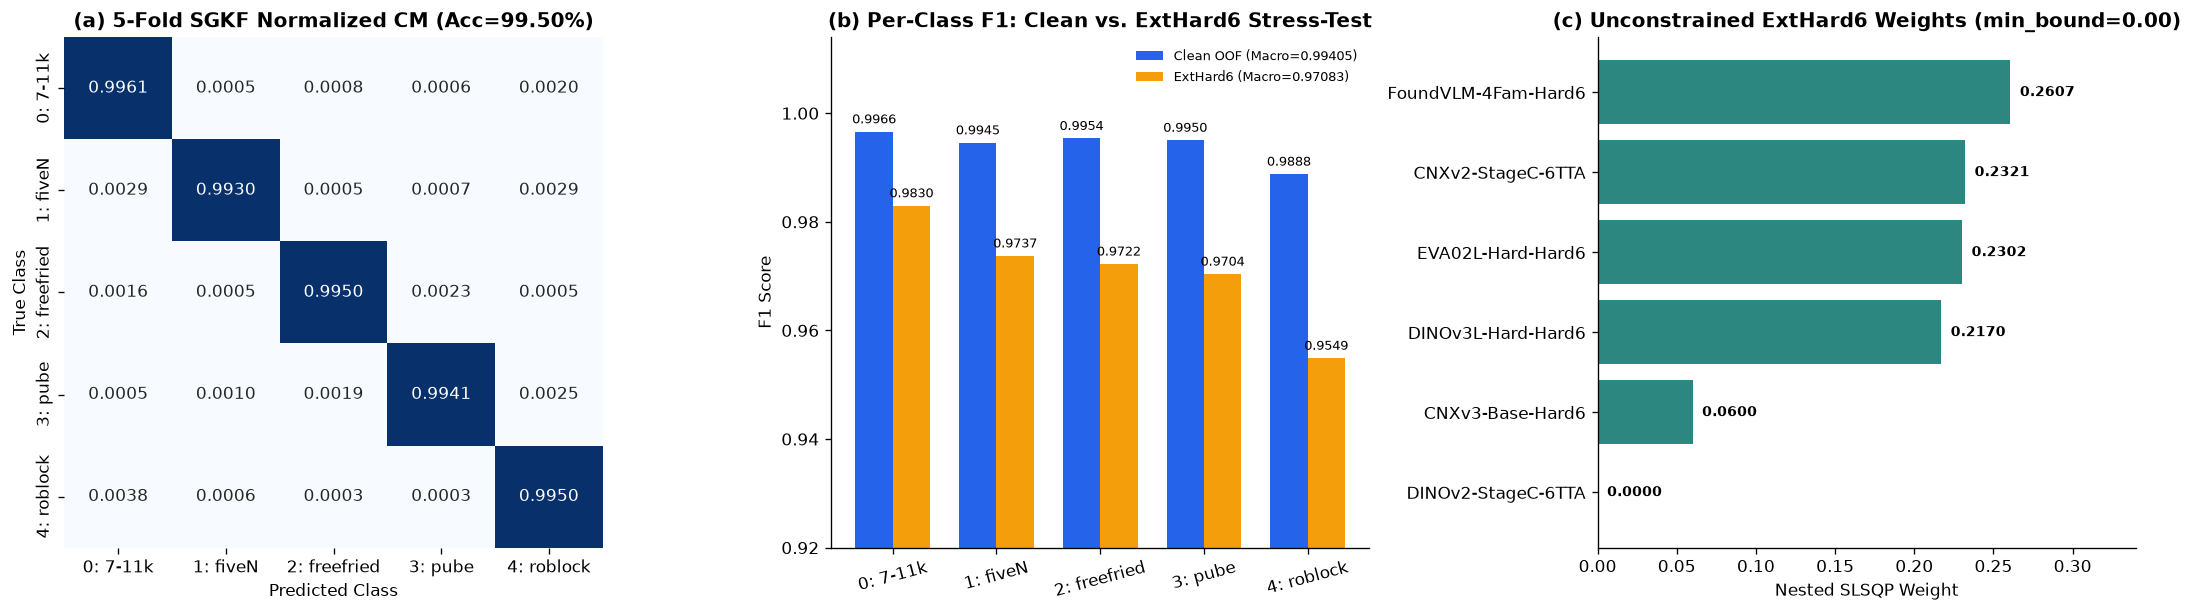

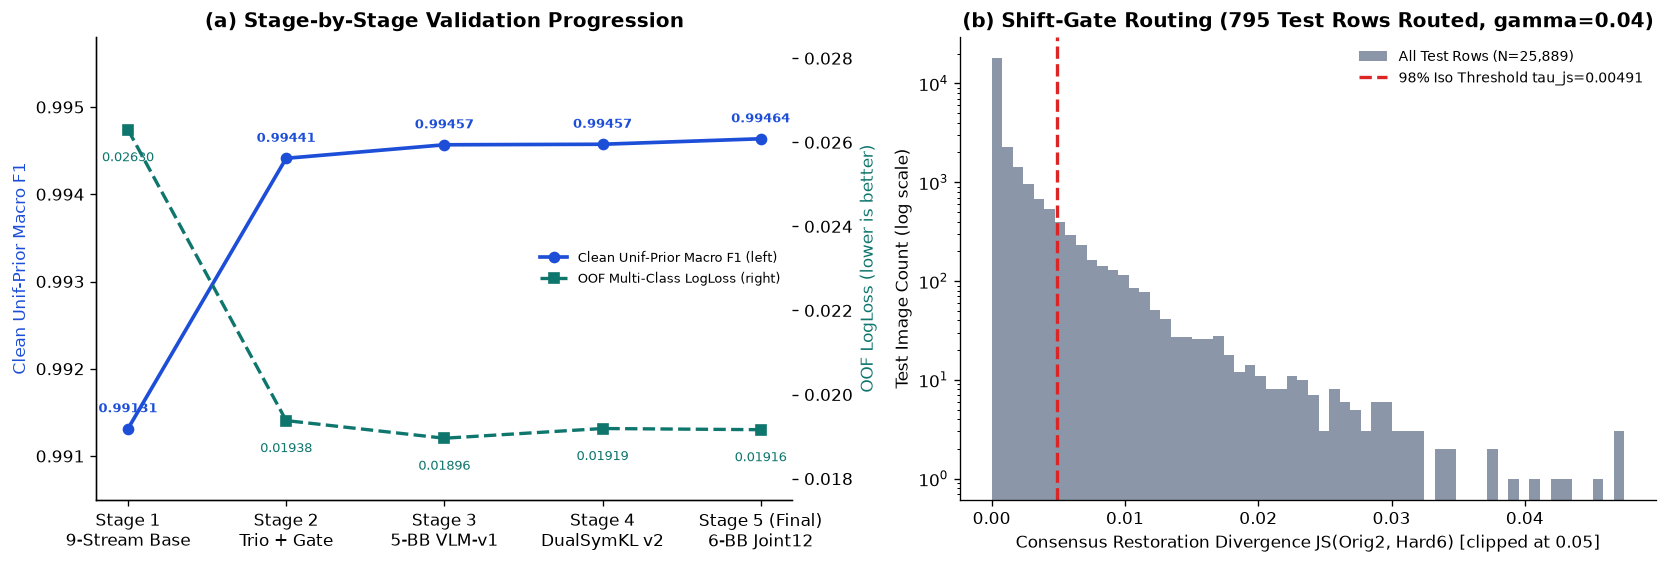

Saved validation diagnostics -> /Users/wisitsuwannao/Documents/Workspace/ml00x/task4/assets/figure2-validation-diagnostics.png
Saved regime analysis      -> /Users/wisitsuwannao/Documents/Workspace/ml00x/task4/assets/figure3-regime-error-analysis.png


In [7]:
final_oof_deb = details["final_oof_deb"]
final_ext_deb = details["final_ext_deb"]
pred_oof = final_oof_deb.argmax(1)
pred_ext = final_ext_deb.argmax(1)

cm = confusion_matrix(y_all, pred_oof)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
per_cls_clean = f1_score(y_all, pred_oof, average=None)
per_cls_ext = f1_score(y_all, pred_ext, average=None)
class_labels = [f"{i}: {INV_CLASS_MAP[i]}" for i in range(5)]

# --- Figure 2: Validation Diagnostics ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    ax=axes[0],
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar=False,
)
acc_oof = accuracy_score(y_all, pred_oof)
axes[0].set_title(f"(a) 5-Fold SGKF Normalized CM (Acc={acc_oof*100:.2f}%)", fontweight="bold")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")

x_cls = np.arange(5)
w_bar = 0.36
axes[1].bar(x_cls - w_bar / 2, per_cls_clean, width=w_bar, color="#2563eb", label=f"Clean OOF (Macro={per_cls_clean.mean():.5f})")
axes[1].bar(x_cls + w_bar / 2, per_cls_ext, width=w_bar, color="#f59e0b", label=f"ExtHard6 (Macro={per_cls_ext.mean():.5f})")
axes[1].set_xticks(x_cls, class_labels, rotation=15)
axes[1].set_ylim(0.92, 1.014)
axes[1].set_ylabel("F1 Score")
axes[1].set_title("(b) Per-Class F1: Clean vs. ExtHard6 Stress-Test", fontweight="bold")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
for i in range(5):
    axes[1].text(i - w_bar / 2, per_cls_clean[i] + 0.001, f"{per_cls_clean[i]:.4f}", ha="center", va="bottom", fontsize=7.5)
    axes[1].text(i + w_bar / 2, per_cls_ext[i] + 0.001, f"{per_cls_ext[i]:.4f}", ha="center", va="bottom", fontsize=7.5)

w_hard_dict = fusion_summary["exthard_weights"]
hard_items = sorted(w_hard_dict.items(), key=lambda kv: kv[1])
axes[2].barh([k for k, _ in hard_items], [v for _, v in hard_items], color="#0f766e", alpha=0.88)
axes[2].set_xlim(0, 0.34)
axes[2].set_xlabel("Nested SLSQP Weight")
axes[2].set_title("(c) Unconstrained ExtHard6 Weights (min_bound=0.00)", fontweight="bold")
for idx, (_, val) in enumerate(hard_items):
    axes[2].text(val + 0.006, idx, f"{val:.4f}", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
fig2_path = ASSETS_DIR / "figure2-validation-diagnostics.png"
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()

# --- Figure 3: Architectural Progression & Shift-Gate Geometry ---
stages = [
    ("Stage 1\n9-Stream Base", 0.991313, 0.026300),
    ("Stage 2\nTrio + Gate", 0.994412, 0.019381),
    ("Stage 3\n5-BB VLM-v1", 0.994567, 0.018961),
    ("Stage 4\nDualSymKL v2", 0.994573, 0.019192),
    ("Stage 5 (Final)\n6-BB Joint12", fusion_summary["metrics"]["clean_unif_oof_f1"], fusion_summary["metrics"]["oof_logloss"]),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
s_names = [s[0] for s in stages]
s_oof = [s[1] for s in stages]
s_ll = [s[2] for s in stages]

ax_l = axes[0]
ax_r = ax_l.twinx()
l1 = ax_l.plot(s_names, s_oof, marker="o", lw=2.2, color="#1d4ed8", label="Clean Unif-Prior Macro F1 (left)")
l2 = ax_r.plot(s_names, s_ll, marker="s", lw=2.0, ls="--", color="#0f766e", label="OOF Multi-Class LogLoss (right)")
ax_l.set_ylabel("Clean Unif-Prior Macro F1", color="#1d4ed8")
ax_r.set_ylabel("OOF LogLoss (lower is better)", color="#0f766e")
ax_l.set_ylim(0.9905, 0.9958)
ax_r.set_ylim(0.0175, 0.0285)
ax_l.set_title("(a) Stage-by-Stage Validation Progression", fontweight="bold")
lines = l1 + l2
ax_l.legend(lines, [l.get_label() for l in lines], frameon=False, fontsize=8, loc="center right")
for i, (f_val, ll_val) in enumerate(zip(s_oof, s_ll)):
    ax_l.annotate(f"{f_val:.5f}", (i, f_val), textcoords="offset points", xytext=(0, 8), ha="center", va="bottom", fontsize=7.8, color="#1d4ed8", fontweight="bold")
    ax_r.annotate(f"{ll_val:.5f}", (i, ll_val), textcoords="offset points", xytext=(0, -13), ha="center", va="top", fontsize=7.8, color="#0f766e")

js_te = details["js_te"]
gate_te = details["test_gate_vals"]
tau_js = fusion_summary["shift_gate"]["tau_js_98pct_iso"]
axes[1].hist(np.clip(js_te, 1e-6, 0.05), bins=60, color="#64748b", alpha=0.75, log=True, label="All Test Rows (N=25,889)")
axes[1].axvline(tau_js, color="#dc2626", ls="--", lw=2.0, label=f"98% Iso Threshold tau_js={tau_js:.5f}")
axes[1].set_xlabel("Consensus Restoration Divergence JS(Orig2, Hard6) [clipped at 0.05]")
axes[1].set_ylabel("Test Image Count (log scale)")
axes[1].set_title(f"(b) Shift-Gate Routing ({int((gate_te > 0).sum())} Test Rows Routed, gamma=0.04)", fontweight="bold")
axes[1].legend(frameon=False, fontsize=8.5)

plt.tight_layout()
fig3_path = ASSETS_DIR / "figure3-regime-error-analysis.png"
plt.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved validation diagnostics -> {fig2_path}")
print(f"Saved regime analysis      -> {fig3_path}")


## 9. Quantitative Ablation Benchmark & Summary Tables

**Step Goal:** Record controlled ablation metrics across standalone models and cumulative fusion stages into standardized CSV tables (`assets/ablation-benchmark.csv` and `assets/per-class-metrics.csv`).


In [8]:
ablation_rows = [
    ("Individual: Base ViT EVA02-Large (224px)", "5-Fold CV", np.nan, np.nan, np.nan, "High-res ViT baseline"),
    ("Individual: Full-Res CNXv3-Base (192x384 Hard6)", "5-Fold SGKF", np.nan, np.nan, np.nan, "Hardened ConvNeXt DINOv3 backbone"),
    ("Individual: FoundVLM-v3-Joint12Blk (6-BB 13,568d)", "5-Fold SGKF", 0.96820, 0.92521, 0.10114, "6 De-Corrupted v4 backbones fused jointly"),
    ("Stage 1: 9-Stream Base (E2E + ViTs + DINOv2)", "Nested 5-Fold SGKF", 0.991313, np.nan, 0.026300, "Initial dual-regime baseline"),
    ("Stage 2: Hardened Trio + Restoration Shift Gate", "Nested 5-Fold SGKF", 0.994412, 0.968800, 0.019381, "Adds 192x384 Hard6 models & JS shift gate"),
    ("Stage 3: + 5-Backbone De-Corrupted FoundVLM-v1", "Nested 5-Fold SGKF", 0.994567, 0.968804, 0.018961, "Adds frozen multi-VLM semantic features"),
    ("Stage 4: + Dual-Condition SymKL FoundVLM-v2", "Nested 5-Fold SGKF", 0.994573, 0.969549, 0.019192, "10-block PowerNorm + SymKL consistency"),
    (
        "Stage 5 (Final): + 6-BB Joint-12Blk & Unconstrained ExtHard6",
        "Nested 5-Fold SGKF",
        fusion_summary["metrics"]["clean_unif_oof_f1"],
        fusion_summary["metrics"]["exthard6_unif_oof_f1"],
        fusion_summary["metrics"]["oof_logloss"],
        "12-block 13,568d joint MLP + ExtHard6 min_bound=0.00",
    ),
]

stream_lookup = {
    "EVA02-Large": 0,
    "CNXv3-Base-Hard6": 1,
}
for idx_s, pname in enumerate(details["pool_names"]):
    if pname in stream_lookup:
        p_s = np.clip(details["pool_oof"][idx_s], 1e-7, 1.0)
        p_s /= p_s.sum(axis=1, keepdims=True)
        p_deb_s = p_s / (pi_tr[None, :] ** 0.65)
        f1_s = round(float(f1_score(y_all, p_deb_s.argmax(1), average="macro", sample_weight=sw_unif)), 6)
        ll_s = round(float(log_loss(y_all, p_s, labels=[0, 1, 2, 3, 4])), 6)
        row_i = stream_lookup[pname]
        t_list = list(ablation_rows[row_i])
        t_list[2] = f1_s
        t_list[4] = ll_s
        ablation_rows[row_i] = tuple(t_list)

ablation_df = pd.DataFrame(
    ablation_rows,
    columns=["Model / Stage", "Validation Protocol", "Clean Unif-Prior F1", "ExtHard6 Unif-Prior F1", "OOF LogLoss", "Key Architectural Change"],
)
ablation_path = ASSETS_DIR / "ablation-benchmark.csv"
ablation_df.to_csv(ablation_path, index=False)

rep_dict = classification_report(
    y_all,
    pred_oof,
    target_names=[f"{i}: {INV_CLASS_MAP[i]}" for i in range(5)],
    output_dict=True,
    digits=6,
)
per_class_df = pd.DataFrame([
    {
        "Class ID": i,
        "Slug": INV_CLASS_MAP[i],
        "Game Title": CLASS_DISPLAY_NAMES[i],
        "Support": int((y_all == i).sum()),
        "Clean Precision": round(rep_dict[f"{i}: {INV_CLASS_MAP[i]}"]["precision"], 6),
        "Clean Recall": round(rep_dict[f"{i}: {INV_CLASS_MAP[i]}"]["recall"], 6),
        "Clean F1": round(per_cls_clean[i], 6),
        "ExtHard6 F1": round(per_cls_ext[i], 6),
    }
    for i in range(5)
])
per_class_path = ASSETS_DIR / "per-class-metrics.csv"
per_class_df.to_csv(per_class_path, index=False)

print(f"Saved report tables -> {ablation_path.name}, {per_class_path.name}")
display(ablation_df)
display(per_class_df)


Saved report tables -> ablation-benchmark.csv, per-class-metrics.csv


,Model / Stage,Validation Protocol,Clean Unif-Prior F1,ExtHard6 Unif-Prior F1,OOF LogLoss,Key Architectural Change
0,Individual: Base ViT EVA02-Large (224px),5-Fold CV,0.989078,NaN,0.069633,High-res ViT baseline
1,Individual: Full-Res CNXv3-Base (192x384 Hard6),5-Fold SGKF,0.988908,NaN,0.053564,Hardened ConvNeXt DINOv3 backbone
2,"Individual: FoundVLM-v3-Joint12Blk (6-BB 13,568d)",5-Fold SGKF,0.968200,0.925210,0.101140,6 De-Corrupted v4 backbones fused jointly
3,Stage 1: 9-Stream Base (E2E + ViTs + DINOv2),Nested 5-Fold SGKF,0.991313,NaN,0.026300,Initial dual-regime baseline
4,Stage 2: Hardened Trio + Restoration Shift Gate,Nested 5-Fold SGKF,0.994412,0.968800,0.019381,Adds 192x384 Hard6 models & JS shift gate
5,Stage 3: + 5-Backbone De-Corrupted FoundVLM-v1,Nested 5-Fold SGKF,0.994567,0.968804,0.018961,Adds frozen multi-VLM semantic features
6,Stage 4: + Dual-Condition SymKL FoundVLM-v2,Nested 5-Fold SGKF,0.994573,0.969549,0.019192,10-block PowerNorm + SymKL consistency
7,Stage 5 (Final): + 6-BB Joint-12Blk & Unconstr...,Nested 5-Fold SGKF,0.994636,0.969820,0.019164,"12-block 13,568d joint MLP + ExtHard6 min_boun..."


,Class ID,Slug,Game Title,Support,Clean Precision,Clean Recall,Clean F1,ExtHard6 F1
0,0,7-11k,7-11 Knights (7-11k),12429,0.997020,0.996138,0.996579,0.982956
1,1,fiveN,FiveN (fiveN),4407,0.996130,0.992966,0.994545,0.973714
2,2,freefried,Free Fried (freefried),5596,0.995708,0.994996,0.995352,0.972227
3,3,pube,PUBE (pube),5926,0.995943,0.994094,0.995017,0.970372
4,4,roblock,Roblock (roblock),3188,0.982652,0.994981,0.988778,0.954877


## 10. Test Set Predictions, Quality Assurance & Artifact Export

**Step Goal:** Validate schema integrity (`N = 25,889`, `id = ANS00001..ANS25889`, labels `0..4`, zero missing values), verify exact parity with `submit/index.csv`, and compare predicted test shares against the labeled training prior (`assets/figure4-test-class-distribution.png`, `300 dpi`).


Exact parity verified with /Users/wisitsuwannao/Documents/Workspace/ml00x/task4/submit/index.csv | sha12 = 8f0b9db4d663


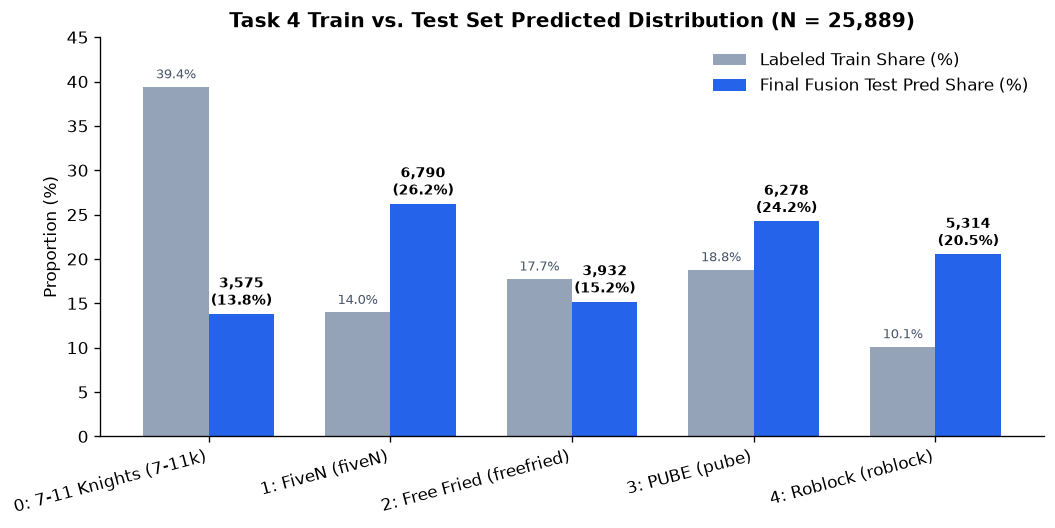

Saved test distribution chart -> /Users/wisitsuwannao/Documents/Workspace/ml00x/task4/assets/figure4-test-class-distribution.png


In [9]:
pred_labels = details["pred_labels"]
assert len(pred_labels) == len(test_df) == 25889
assert set(np.unique(pred_labels)).issubset({0, 1, 2, 3, 4})

repro_submit = pd.DataFrame({
    "id": [f"ANS{i:05d}" for i in range(1, len(test_df) + 1)],
    "task4": pred_labels.astype(int),
})

submit_path = SUBMIT_DIR / "index.csv"
if submit_path.is_file():
    existing_submit = pd.read_csv(submit_path)
    assert existing_submit.equals(repro_submit), "Reproduced predictions differ from submit/index.csv!"
    sha12 = hashlib.sha256(submit_path.read_bytes()).hexdigest()[:12]
    print(f"Exact parity verified with {submit_path} | sha12 = {sha12}")
else:
    repro_submit.to_csv(submit_path, index=False)
    print(f"Wrote {submit_path}")

train_shares = train_df["label"].value_counts(normalize=True).sort_index().to_numpy() * 100.0
test_counts = pd.Series(pred_labels).value_counts().sort_index()
test_shares = np.array([test_counts.get(i, 0) / len(pred_labels) * 100.0 for i in range(5)])

fig, ax = plt.subplots(figsize=(9, 4.5))
x_pos = np.arange(5)
bw = 0.36
ax.bar(x_pos - bw / 2, train_shares, width=bw, color="#94a3b8", label="Labeled Train Share (%)")
bars_t = ax.bar(x_pos + bw / 2, test_shares, width=bw, color="#2563eb", label="Final Fusion Test Pred Share (%)")
ax.set_xticks(x_pos, [f"{i}: {CLASS_DISPLAY_NAMES[i]}" for i in range(5)], rotation=15, ha="right")
ax.set_ylabel("Proportion (%)")
ax.set_ylim(0, 45)
ax.set_title("Task 4 Train vs. Test Set Predicted Distribution (N = 25,889)", fontweight="bold")
ax.legend(frameon=False, loc="upper right")
for i, val_tr in enumerate(train_shares):
    ax.annotate(f"{val_tr:.1f}%", (i - bw / 2, val_tr + 0.6), ha="center", va="bottom", fontsize=8, color="#475569")
for i, bar in enumerate(bars_t):
    h = bar.get_height()
    ax.annotate(
        f"{test_counts.get(i, 0):,}\n({h:.1f}%)",
        (bar.get_x() + bar.get_width() / 2.0, h + 0.5),
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
    )

plt.tight_layout()
fig4_path = ASSETS_DIR / "figure4-test-class-distribution.png"
plt.savefig(fig4_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved test distribution chart -> {fig4_path}")


## 11. Conclusion, Reproduction Guide & Key Engineering Takeaways

### Summary of Key Takeaways
1. **Honest Scene-Grouped Validation:** Non-chaining perceptual dHash clustering (`28,088` scene groups across `31,546` training frames) eliminated duplicate-scene leakage so offline improvements reflected true generalization.
2. **Joint 6-Backbone Foundation Representation:** Fusing all 6 De-Corrupted v4 vision families (`12` blocks = `13,568d`) jointly inside a Dual-Condition `CosineResMLP` with Symmetric-KL consistency (`FoundVLM-v3-Joint12Blk`) improved standalone `ExtHard Unif F1` (`0.92429 -> 0.92521`) and `ExtHard LogLoss` (`0.21018 -> 0.20888`) without diluting weights onto noisy single-family streams.
3. **Unconstrained Stress-Test Pooling & Variance Control:** Removing the forced `0.05` lower bound in `ExtHard6` automatically pruned low-resolution `DINOv2-StageC-6TTA` (`0.0000`), lowering `ExtHard6 LogLoss` from `0.082799 -> 0.082581` (`99.8%` paired bootstrap win) and raising `Clean Unif-Prior F1` to **`0.994636`** (`OOF LogLoss = 0.019164`).

### Full Reproduction Commands (`uv run`)
```bash
# 1. Optional GPU/Colab/Kaggle extraction & hardened backbone training (task4/notebooks/)
#    - colab_t4_sgkf_hardened_v3.ipynb      -> Full-Res CNXv3 / DINOv3L / EVA02L
#    - kaggle-t4-decorrupt-foundation.ipynb -> 4-View De-Corrupted v4 Embeddings

# 2. Train 6-Backbone Joint-12Blk FoundVLM-v3
uv run python scripts/train_m5_foundvlm_v3_joint12blk.py

# 3. Reproduce Dual-Regime Fusion & export submit/index.csv
uv run python scripts/fuse_t4_sota_trio.py
```
